In [2]:
# Import the necessary libraries and the class
from   climateScenario import climateScenario
import matplotlib.pyplot as plt
import pandas as pd

In [24]:
# Run the climateScenario for the historical period
hist = climateScenario( 'historical', ecs = 3, end_year = 2025 )
hist.integrate()

# Get the observations
hist_obs = pd.read_csv("data/observed_climate_1750_2025.csv")
hist_obs.head()


,year,GMST_obs_C,CO2_obs_ppm,CH4_obs_ppb
0,1750,NaN,NaN,NaN
1,1751,NaN,NaN,NaN
2,1752,NaN,277.229680,NaN
3,1753,NaN,277.222955,NaN
4,1754,NaN,277.216229,NaN


Model baseline (1850-1900): 0.02739490660429161
          GMST    Catm_CO2    RF_CO2  emissions_CO2  cumulativeEmissions_CO2  \
year                                                                           
1750  0.000000  277.150000  0.000000   0.000000e+00             0.000000e+00   
1751  0.026770  277.150000  0.000000   5.472835e+09             5.472835e+09   
1752  0.045734  277.150614  0.000010   1.105004e+10             1.652288e+10   
1753  0.057568  277.151881  0.000033   1.672609e+10             3.324897e+10   
1754  0.063223  277.153778  0.000068   2.251024e+10             5.575921e+10   
...        ...         ...       ...            ...                      ...   
2021  1.399386  443.014148  2.514431   4.062341e+13             2.380862e+15   
2022  1.431660  445.712763  2.547906   4.090627e+13             2.421768e+15   
2023  1.464334  448.419295  2.581300   4.118912e+13             2.462957e+15   
2024  1.495879  451.134256  2.614622   4.147197e+13             2.504429

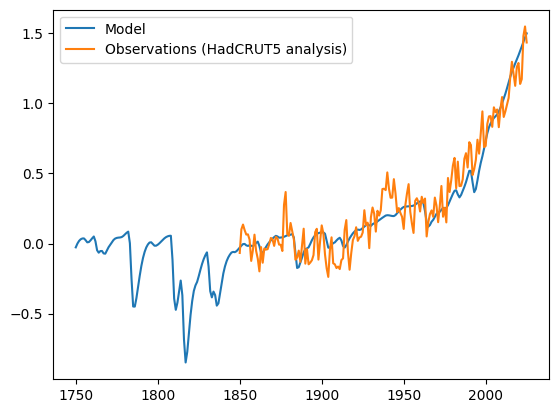

In [27]:
# Temperature comparison
model_baseline = hist.outdf['GMST'].loc[1850:1900].mean()
plt.plot( hist.outdf.index, hist.outdf['GMST'] -  model_baseline, label='Model')
plt.plot( hist_obs['year'], hist_obs['GMST_obs_C'], label='Observations (HadCRUT5 analysis)')
plt.legend()
print("Model baseline (1850-1900):", model_baseline)
print( hist.outdf )


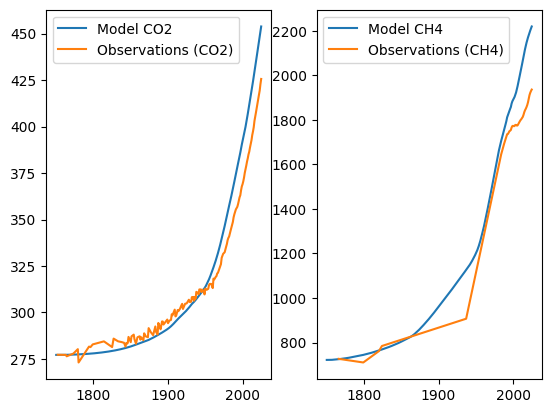

In [28]:
# CO2 and methane concentration comparison (in two subplots)
plt.subplot(1, 2, 1)
plt.plot( hist.outdf.index, hist.outdf['Catm_CO2'], label='Model CO2')
plt.plot( hist_obs['year'], hist_obs['CO2_obs_ppm'], label='Observations (CO2)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot( hist.outdf.index, hist.outdf['Catm_CH4'], label='Model CH4')
plt.plot( hist_obs['year'], hist_obs['CH4_obs_ppb'], label='Observations (CH4)')
plt.legend()    